# 02 — Context-access intervention

Reproduces the confirmatory Qwen2.5 context-access result and the independent SmolLM2 replication from frozen paired-analysis artifacts.

Expected inputs are under `data/raid_pilot/context_access_confirmatory/` and `data/raid_pilot/context_access_cross_generator/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
PROJECT_ROOT = ROOT.parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)

ROOT: ..


In [2]:
Q_candidates = [
    DATA / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_confirmatory",
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_confirmatory",
]

S_candidates = [
    DATA / "raid_pilot" / "context_access_cross_generator",
    PROJECT_ROOT / "data" / "raid_pilot" / "context_access_cross_generator",
    PROJECT_ROOT / "results" / "raid_pilot" / "context_access_cross_generator",
]

Q = next(
    (p for p in Q_candidates if (p / "confirmatory_results.csv").exists()),
    None,
)

S = next(
    (p for p in S_candidates if (p / "cross_generator_results.csv").exists()),
    None,
)

assert Q is not None, (
    "Could not find confirmatory_results.csv. Checked:\n"
    + "\n".join(map(str, Q_candidates))
)

assert S is not None, (
    "Could not find cross_generator_results.csv. Checked:\n"
    + "\n".join(map(str, S_candidates))
)

qr = pd.read_csv(Q / "confirmatory_results.csv")
qp = pd.read_parquet(Q / "confirmatory_pairs.parquet")

sr = pd.read_csv(S / "cross_generator_results.csv")
sp = pd.read_parquet(S / "cross_generator_pairs.parquet")

print("Q:", Q)
print("S:", S)
print(qr.shape, qp.shape, sr.shape, sp.shape)

Q: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_confirmatory
S: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/context_access_cross_generator
(12, 9) (60, 12) (12, 9) (40, 12)


In [3]:
metric_to_k={"delta_u32":32,"delta_u128":128,"delta_u256":256}
def prep(df,name):
    z=df[(df.scope=="combined") & df.metric.isin(metric_to_k)].copy(); z["k"]=z.metric.map(metric_to_k); z["generator"]=name
    return z[["generator","k","n","mean","ci_low","ci_high"]].sort_values("k")
summary=pd.concat([prep(qr,"Qwen2.5-1.5B-Instruct"),prep(sr,"SmolLM2")],ignore_index=True)
summary.to_csv(RESULTS/"context_access_intervention_summary.csv",index=False); display(summary)

,generator,k,n,mean,ci_low,ci_high
0,Qwen2.5-1.5B-Instruct,32,60,-0.019923,-0.257304,0.226189
1,Qwen2.5-1.5B-Instruct,128,60,-0.405133,-0.752141,-0.065970
2,Qwen2.5-1.5B-Instruct,256,60,-0.406799,-0.741889,-0.068354
3,SmolLM2,32,40,-0.176348,-0.455952,0.107503
4,SmolLM2,128,40,-0.492357,-0.817292,-0.165058
5,SmolLM2,256,40,-0.577834,-0.918320,-0.249686


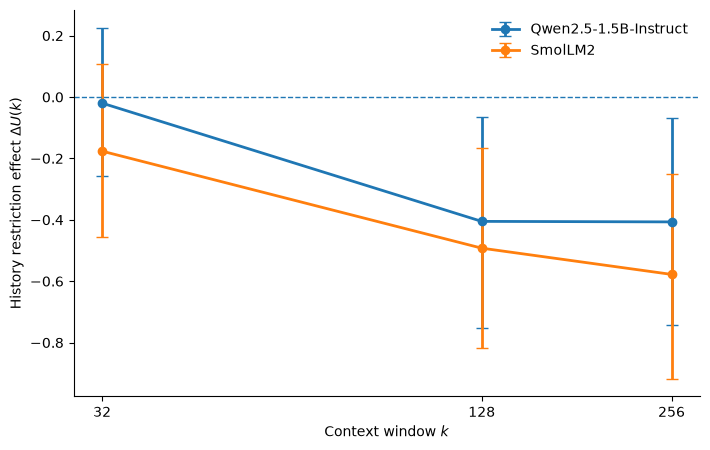

In [4]:
fig,ax=plt.subplots(figsize=(7.2,4.6))
for name,s in summary.groupby("generator"):
    s=s.sort_values("k"); y=s["mean"].to_numpy(); err=np.vstack([y-s.ci_low.to_numpy(),s.ci_high.to_numpy()-y])
    ax.errorbar(s.k,y,yerr=err,marker="o",linewidth=2,capsize=4,label=name)
ax.axhline(0,ls="--",lw=1); ax.set_xscale("log",base=2); ax.set_xticks([32,128,256]); ax.set_xticklabels([32,128,256]); ax.set_xlabel("Context window $k$"); ax.set_ylabel(r"History restriction effect $\Delta U(k)$"); ax.legend(frameon=False); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); fig.tight_layout(); fig.savefig(FIGURES/"context_access_intervention.pdf",bbox_inches="tight"); fig.savefig(FIGURES/"context_access_intervention.png",dpi=300,bbox_inches="tight"); plt.show()